<a href="https://colab.research.google.com/github/suhail100506/DS-PROJECT/blob/main/DS_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all five CSV files
customers = pd.read_csv("/content/customers.csv")
usage = pd.read_csv("/content/usage.csv")
billing = pd.read_csv("/content/billing.csv")
support = pd.read_csv("/content/support.csv")
service = pd.read_csv("/content/service.csv")

print("All five datasets loaded successfully!")

datasets = {
    "Customers": customers,
    "Usage": usage,
    "Billing": billing,
    "Support": support,
    "Service": service
}

for name, df in datasets.items():
    print(f"\n{name} Dataset")
    print("Rows and columns:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())


All five datasets loaded successfully!

Customers Dataset
Rows and columns: (1512, 7)
Columns: ['customer_id', 'age', 'tenure_months', 'plan', 'region', 'contract_type', 'churn']


,customer_id,age,tenure_months,plan,region,contract_type,churn
0,CS00001,19,67.0,STANDARD,South,Monthly,0
1,CS00002,63,69.0,Family,South,Monthly,0
2,CS00003,40,4.0,Premium,West,Monthly,1
3,CS00004,18,69.0,Standard,West,Annual,0
4,CS00005,61,20.0,Premium,South,Monthly,0



Usage Dataset
Rows and columns: (1435, 5)
Columns: ['customer_id', 'voice_minutes', 'data_gb', 'sms_count', 'monthly_usage_score']


,customer_id,voice_minutes,data_gb,sms_count,monthly_usage_score
0,CS00001,321.1,5.04,80,0.422
1,CS00002,641.8,5.26,71,0.658
2,CS00003,271.9,12.32,56,0.506
3,CS00004,364.6,8.60,79,0.524
4,CS00005,499.3,14.92,63,0.736



Billing Dataset
Rows and columns: (1510, 5)
Columns: ['customer_id', 'monthly_charges', 'payment_status', 'late_payments_12m', 'total_charges']


,customer_id,monthly_charges,payment_status,late_payments_12m,total_charges
0,CS00001,791.17,Paid,0,53008.37
1,CS00002,1654.81,Paid,1,114181.59
2,CS00003,1326.21,Paid,1,5304.86
3,CS00004,709.88,Late,2,48981.70
4,CS00005,1209.66,Late,2,24193.20



Support Dataset
Rows and columns: (1500, 5)
Columns: ['customer_id', 'complaints_12m', 'tickets_12m', 'avg_resolution_hours', 'support_history_complete']


,customer_id,complaints_12m,tickets_12m,avg_resolution_hours,support_history_complete
0,CS00001,0.0,1.0,6.3,True
1,CS00002,1.0,3.0,31.9,True
2,CS00003,NaN,NaN,NaN,False
3,CS00004,1.0,3.0,28.7,True
4,CS00005,0.0,0.0,10.9,True



Service Dataset
Rows and columns: (1500, 5)
Columns: ['customer_id', 'network_issues_12m', 'outages_12m', 'plan_changes_12m', 'last_service_issue_days_ago']


,customer_id,network_issues_12m,outages_12m,plan_changes_12m,last_service_issue_days_ago
0,CS00001,0,0,4,159
1,CS00002,0,1,1,159
2,CS00003,1,1,0,11
3,CS00004,2,0,0,123
4,CS00005,2,0,0,248


In [2]:

for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(name.upper())
    print("Missing values:\n", df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())

print("\nDuplicate customer IDs:",
      customers["customer_id"].duplicated().sum())



CUSTOMERS
Missing values:
 customer_id       0
age               0
tenure_months    12
plan              0
region            0
contract_type     0
churn             0
dtype: int64
Duplicate rows: 12

USAGE
Missing values:
 customer_id             0
voice_minutes           0
data_gb                35
sms_count               0
monthly_usage_score     0
dtype: int64
Duplicate rows: 0

BILLING
Missing values:
 customer_id          0
monthly_charges      0
payment_status       0
late_payments_12m    0
total_charges        0
dtype: int64
Duplicate rows: 10

SUPPORT
Missing values:
 customer_id                   0
complaints_12m              191
tickets_12m                 191
avg_resolution_hours        191
support_history_complete      0
dtype: int64
Duplicate rows: 0

SERVICE
Missing values:
 customer_id                    0
network_issues_12m             0
outages_12m                    0
plan_changes_12m               0
last_service_issue_days_ago    0
dtype: int64
Duplicate rows: 0

Du

In [3]:

# Check customer data
print("Customer dataset shape:", customers.shape)
print("\nMissing values:")
display(customers.isnull().sum().to_frame("Missing Count"))

print("\nDuplicate customer IDs:",
      customers["customer_id"].duplicated().sum())

display(customers.head(10))


Customer dataset shape: (1512, 7)

Missing values:


,Missing Count
customer_id,0
age,0
tenure_months,12
plan,0
region,0
contract_type,0
churn,0



Duplicate customer IDs: 12


,customer_id,age,tenure_months,plan,region,contract_type,churn
0,CS00001,19,67.0,STANDARD,South,Monthly,0
1,CS00002,63,69.0,Family,South,Monthly,0
2,CS00003,40,4.0,Premium,West,Monthly,1
3,CS00004,18,69.0,Standard,West,Annual,0
4,CS00005,61,20.0,Premium,South,Monthly,0
5,CS00006,56,28.0,Basic,East,Monthly,0
6,CS00007,25,46.0,Premium,West,Two-Year,0
7,CS00008,30,24.0,Standard,North,Annual,1
8,CS00009,63,29.0,Premium,East,Two-Year,1
9,CS00010,41,55.0,Basic,East,Monthly,0


In [4]:

# Make a copy so the original data remains unchanged
customers_clean = customers.copy()

# Standardize subscription plan names
customers_clean["plan"] = (
    customers_clean["plan"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Standardize common plan-name variations
customers_clean["plan"] = customers_clean["plan"].replace({
    "basic plan": "basic",
    "standard plan": "standard",
    "premium plan": "premium",
    "basic ": "basic",
    "standard ": "standard",
    "premium ": "premium"
})

# Remove duplicate customer records
customers_clean = customers_clean.drop_duplicates(
    subset="customer_id", keep="first"
)

# Show missing values before handling them
print("Missing values before handling:")
display(customers_clean.isnull().sum().to_frame("Missing Count"))

print("Cleaned customer dataset shape:", customers_clean.shape)
display(customers_clean.head())


Missing values before handling:


,Missing Count
customer_id,0
age,0
tenure_months,12
plan,0
region,0
contract_type,0
churn,0


Cleaned customer dataset shape: (1500, 7)


,customer_id,age,tenure_months,plan,region,contract_type,churn
0,CS00001,19,67.0,standard,South,Monthly,0
1,CS00002,63,69.0,family,South,Monthly,0
2,CS00003,40,4.0,premium,West,Monthly,1
3,CS00004,18,69.0,standard,West,Annual,0
4,CS00005,61,20.0,premium,South,Monthly,0


In [5]:

# Create copies of the other datasets
usage_clean = usage.copy()
billing_clean = billing.copy()
support_clean = support.copy()
service_clean = service.copy()

# Remove exact duplicate rows
usage_clean = usage_clean.drop_duplicates()
billing_clean = billing_clean.drop_duplicates()
support_clean = support_clean.drop_duplicates()
service_clean = service_clean.drop_duplicates()

# Standardize customer IDs
for df in [
    customers_clean, usage_clean, billing_clean,
    support_clean, service_clean
]:
    df["customer_id"] = df["customer_id"].astype("string").str.strip()

# Check the results
for name, df in {
    "Customers": customers_clean,
    "Usage": usage_clean,
    "Billing": billing_clean,
    "Support": support_clean,
    "Service": service_clean
}.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")


Customers: 1500 rows, 7 columns
Usage: 1435 rows, 5 columns
Billing: 1500 rows, 5 columns
Support: 1500 rows, 5 columns
Service: 1500 rows, 5 columns


In [6]:

for name, df in {
    "Usage": usage_clean,
    "Billing": billing_clean,
    "Support": support_clean,
    "Service": service_clean
}.items():
    print(f"\n{name} columns:")
    print(df.columns.tolist())
    display(df.head(3))



Usage columns:
['customer_id', 'voice_minutes', 'data_gb', 'sms_count', 'monthly_usage_score']


,customer_id,voice_minutes,data_gb,sms_count,monthly_usage_score
0,CS00001,321.1,5.04,80,0.422
1,CS00002,641.8,5.26,71,0.658
2,CS00003,271.9,12.32,56,0.506



Billing columns:
['customer_id', 'monthly_charges', 'payment_status', 'late_payments_12m', 'total_charges']


,customer_id,monthly_charges,payment_status,late_payments_12m,total_charges
0,CS00001,791.17,Paid,0,53008.37
1,CS00002,1654.81,Paid,1,114181.59
2,CS00003,1326.21,Paid,1,5304.86



Support columns:
['customer_id', 'complaints_12m', 'tickets_12m', 'avg_resolution_hours', 'support_history_complete']


,customer_id,complaints_12m,tickets_12m,avg_resolution_hours,support_history_complete
0,CS00001,0.0,1.0,6.3,True
1,CS00002,1.0,3.0,31.9,True
2,CS00003,NaN,NaN,NaN,False



Service columns:
['customer_id', 'network_issues_12m', 'outages_12m', 'plan_changes_12m', 'last_service_issue_days_ago']


,customer_id,network_issues_12m,outages_12m,plan_changes_12m,last_service_issue_days_ago
0,CS00001,0,0,4,159
1,CS00002,0,1,1,159
2,CS00003,1,1,0,11


In [7]:

# Step 5: Aggregate customer-level data

# Usage data
usage_agg = usage_clean.groupby("customer_id", as_index=False).agg({
    "voice_minutes": "mean",
    "data_gb": "mean",
    "sms_count": "mean",
    "monthly_usage_score": "mean"
})

# Billing data
billing_agg = billing_clean.groupby("customer_id", as_index=False).agg({
    "monthly_charges": "mean",
    "late_payments_12m": "max",
    "total_charges": "max"
})

# Most recent/common payment status
payment_status = (
    billing_clean.groupby("customer_id")["payment_status"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    .reset_index()
)

billing_agg = billing_agg.merge(
    payment_status, on="customer_id", how="left"
)

# Support data
support_agg = support_clean.groupby("customer_id", as_index=False).agg({
    "complaints_12m": "sum",
    "tickets_12m": "sum",
    "avg_resolution_hours": "mean",
    "support_history_complete": "max"
})

# Service data
service_agg = service_clean.groupby("customer_id", as_index=False).agg({
    "network_issues_12m": "sum",
    "outages_12m": "sum",
    "plan_changes_12m": "sum",
    "last_service_issue_days_ago": "min"
})

# Merge everything with the customer master table
churn_data = customers_clean.copy()

for df in [usage_agg, billing_agg, support_agg, service_agg]:
    churn_data = churn_data.merge(
        df, on="customer_id", how="left", validate="one_to_one"
    )

print("Merged dataset shape:", churn_data.shape)
print("Unique customer IDs:", churn_data["customer_id"].nunique())
display(churn_data.head())


Merged dataset shape: (1500, 23)
Unique customer IDs: 1500


,customer_id,age,tenure_months,plan,region,contract_type,churn,voice_minutes,data_gb,sms_count,...,total_charges,payment_status,complaints_12m,tickets_12m,avg_resolution_hours,support_history_complete,network_issues_12m,outages_12m,plan_changes_12m,last_service_issue_days_ago
0,CS00001,19,67.0,standard,South,Monthly,0,321.1,5.04,80.0,...,53008.37,Paid,0.0,1.0,6.3,True,0,0,4,159
1,CS00002,63,69.0,family,South,Monthly,0,641.8,5.26,71.0,...,114181.59,Paid,1.0,3.0,31.9,True,0,1,1,159
2,CS00003,40,4.0,premium,West,Monthly,1,271.9,12.32,56.0,...,5304.86,Paid,0.0,0.0,NaN,False,1,1,0,11
3,CS00004,18,69.0,standard,West,Annual,0,364.6,8.60,79.0,...,48981.70,Late,1.0,3.0,28.7,True,2,0,0,123
4,CS00005,61,20.0,premium,South,Monthly,0,499.3,14.92,63.0,...,24193.20,Late,0.0,0.0,10.9,True,2,0,0,248


In [8]:

# Inspect missing values
missing_summary = pd.DataFrame({
    "Missing Count": churn_data.isnull().sum(),
    "Missing Percentage": (
        churn_data.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Percentage", ascending=False
    )
)


,Missing Count,Missing Percentage
avg_resolution_hours,191,12.73
data_gb,100,6.67
sms_count,65,4.33
voice_minutes,65,4.33
monthly_usage_score,65,4.33
tenure_months,12,0.80
customer_id,0,0.00
churn,0,0.00
contract_type,0,0.00
region,0,0.00


In [9]:

# Fill numeric missing values using column medians
numeric_cols = churn_data.select_dtypes(
    include="number"
).columns

for col in numeric_cols:
    churn_data[col] = churn_data[col].fillna(
        churn_data[col].median()
    )

# Fill categorical missing values with the mode
categorical_cols = churn_data.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in categorical_cols:
    if churn_data[col].isnull().any():
        mode_values = churn_data[col].mode()
        if not mode_values.empty:
            churn_data[col] = churn_data[col].fillna(
                mode_values.iloc[0]
            )

print("Remaining missing values:",
      churn_data.isnull().sum().sum())
print("Final shape:", churn_data.shape)


Remaining missing values: 0
Final shape: (1500, 23)


Churn column values:
churn
0    1032
1     468
Name: count, dtype: int64

Overall churn rate: 31.20%


,plan,customers,churned,churn_rate
0,basic,456,162,35.526316
1,family,182,66,36.263736
2,premium,342,90,26.315789
3,standard,520,150,28.846154


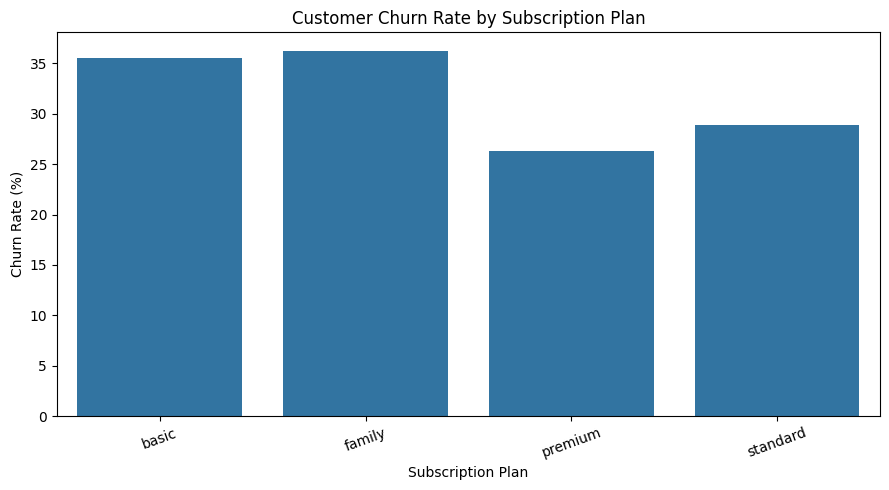

In [10]:

# Overall churn rate
print("Churn column values:")
print(churn_data["churn"].value_counts(dropna=False))

churn_rate = churn_data["churn"].mean() * 100
print(f"\nOverall churn rate: {churn_rate:.2f}%")

# Churn by plan
plan_analysis = churn_data.groupby("plan", dropna=False).agg(
    customers=("customer_id", "nunique"),
    churned=("churn", "sum"),
    churn_rate=("churn", "mean")
).reset_index()

plan_analysis["churn_rate"] *= 100

display(plan_analysis)

plt.figure(figsize=(9, 5))
sns.barplot(data=plan_analysis, x="plan", y="churn_rate")
plt.title("Customer Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [11]:

from google.colab import files

churn_data.to_csv(
    "/content/cleaned_customer_churn.csv",
    index=False
)

files.download("/content/cleaned_customer_churn.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Check the actual tenure column name
print(churn_data.columns.tolist())


['customer_id', 'age', 'tenure_months', 'plan', 'region', 'contract_type', 'churn', 'voice_minutes', 'data_gb', 'sms_count', 'monthly_usage_score', 'monthly_charges', 'late_payments_12m', 'total_charges', 'payment_status', 'complaints_12m', 'tickets_12m', 'avg_resolution_hours', 'support_history_complete', 'network_issues_12m', 'outages_12m', 'plan_changes_12m', 'last_service_issue_days_ago']


,tenure_group,total_customers,churned,churn_rate
0,0-6 months,131,80,61.068702
1,7-12 months,125,48,38.400000
2,13-24 months,235,62,26.382979
3,25-48 months,518,133,25.675676
4,48+ months,491,145,29.531568


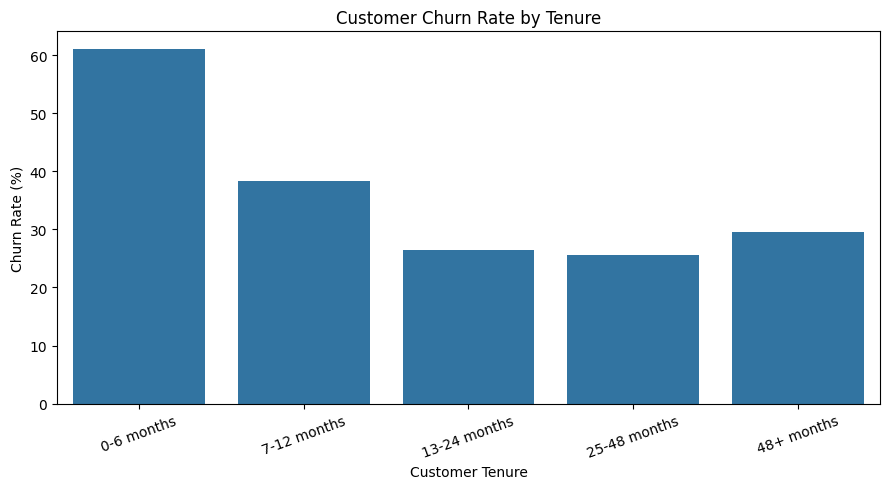

In [13]:

# Group customers by tenure
churn_data["tenure_group"] = pd.cut(
    churn_data["tenure_months"],
    bins=[-1, 6, 12, 24, 48, float("inf")],
    labels=["0-6 months", "7-12 months",
            "13-24 months", "25-48 months", "48+ months"]
)

tenure_analysis = churn_data.groupby(
    "tenure_group", observed=False
).agg(
    total_customers=("customer_id", "nunique"),
    churned=("churn", "sum"),
    churn_rate=("churn", "mean")
).reset_index()

tenure_analysis["churn_rate"] *= 100
display(tenure_analysis)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=tenure_analysis,
    x="tenure_group",
    y="churn_rate"
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [14]:

complaint_analysis = churn_data.groupby("churn").agg(
    customers=("customer_id", "nunique"),
    avg_complaints=("complaints_12m", "mean"),
    avg_tickets=("tickets_12m", "mean"),
    avg_resolution_hours=("avg_resolution_hours", "mean")
).reset_index()

display(complaint_analysis)


,churn,customers,avg_complaints,avg_tickets,avg_resolution_hours
0,0,1032,0.716085,1.405039,23.293411
1,1,468,0.848291,1.512821,23.058333


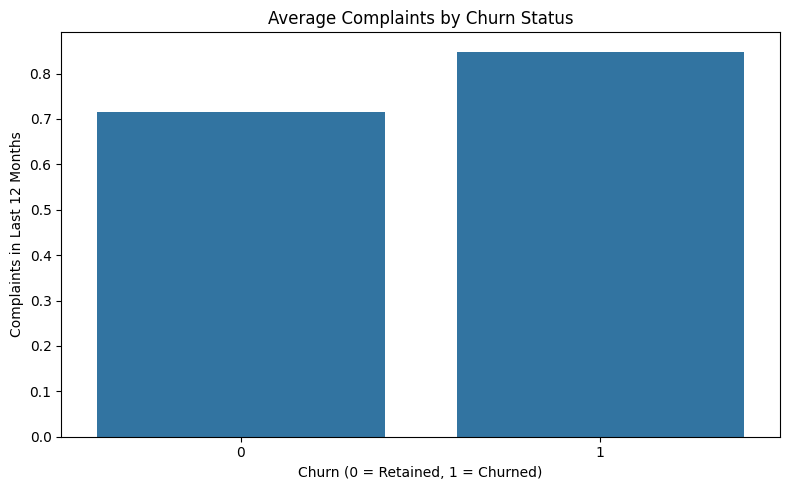

In [15]:

plt.figure(figsize=(8, 5))
sns.barplot(
    data=churn_data,
    x="churn",
    y="complaints_12m",
    errorbar=None
)
plt.title("Average Complaints by Churn Status")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Complaints in Last 12 Months")
plt.tight_layout()
plt.show()


,churn,customers,avg_late_payments,avg_monthly_charges
0,0,1032,0.681202,963.497016
1,1,468,0.927350,926.376816


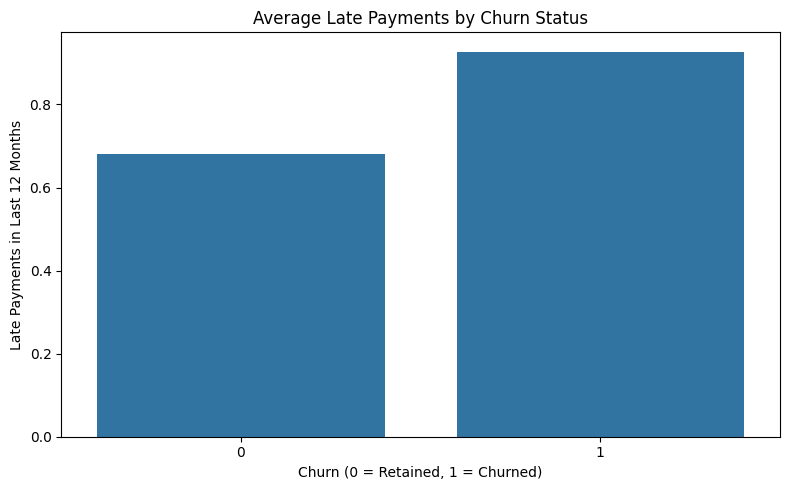

In [16]:

payment_analysis = churn_data.groupby("churn").agg(
    customers=("customer_id", "nunique"),
    avg_late_payments=("late_payments_12m", "mean"),
    avg_monthly_charges=("monthly_charges", "mean")
).reset_index()

display(payment_analysis)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=churn_data,
    x="churn",
    y="late_payments_12m",
    errorbar=None
)
plt.title("Average Late Payments by Churn Status")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Late Payments in Last 12 Months")
plt.tight_layout()
plt.show()


,voice_minutes,data_gb,sms_count,monthly_usage_score
churn,,,,
0,422.215504,10.132694,74.531977,0.595399
1,419.545940,9.891047,74.756410,0.588248


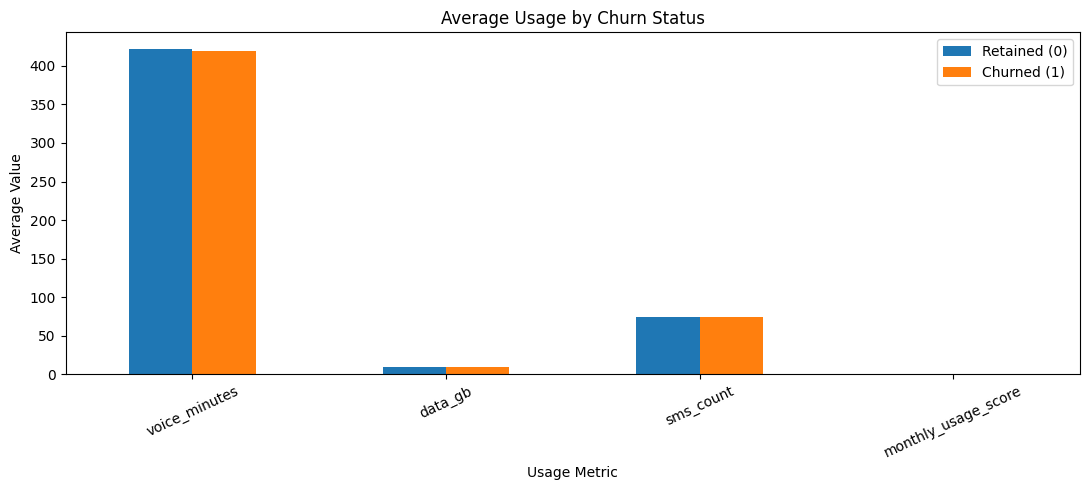

In [17]:

usage_columns = [
    "voice_minutes",
    "data_gb",
    "sms_count",
    "monthly_usage_score"
]

usage_analysis = churn_data.groupby("churn")[usage_columns].mean()
display(usage_analysis)

usage_analysis.T.plot(
    kind="bar",
    figsize=(11, 5)
)
plt.title("Average Usage by Churn Status")
plt.xlabel("Usage Metric")
plt.ylabel("Average Value")
plt.xticks(rotation=25)
plt.legend(["Retained (0)", "Churned (1)"])
plt.tight_layout()
plt.show()


In [18]:

# High complaint indicator
churn_data["high_complaints"] = (
    churn_data["complaints_12m"] >= 2
).astype(int)

# Late payment indicator
churn_data["has_late_payments"] = (
    churn_data["late_payments_12m"] > 0
).astype(int)

# Low usage indicator based on the median
usage_median = churn_data["monthly_usage_score"].median()

churn_data["low_usage"] = (
    churn_data["monthly_usage_score"] < usage_median
).astype(int)

# High network issue indicator
churn_data["has_network_issues"] = (
    churn_data["network_issues_12m"] > 0
).astype(int)

display(churn_data[[
    "customer_id", "high_complaints",
    "has_late_payments", "low_usage",
    "has_network_issues", "churn"
]].head(10))


,customer_id,high_complaints,has_late_payments,low_usage,has_network_issues,churn
0,CS00001,0,0,1,0,0
1,CS00002,0,1,0,0,0
2,CS00003,0,1,1,1,1
3,CS00004,0,1,1,1,0
4,CS00005,0,1,0,1,0
5,CS00006,0,1,0,1,0
6,CS00007,0,1,1,1,0
7,CS00008,0,1,0,0,1
8,CS00009,1,1,0,0,1
9,CS00010,0,0,0,0,0


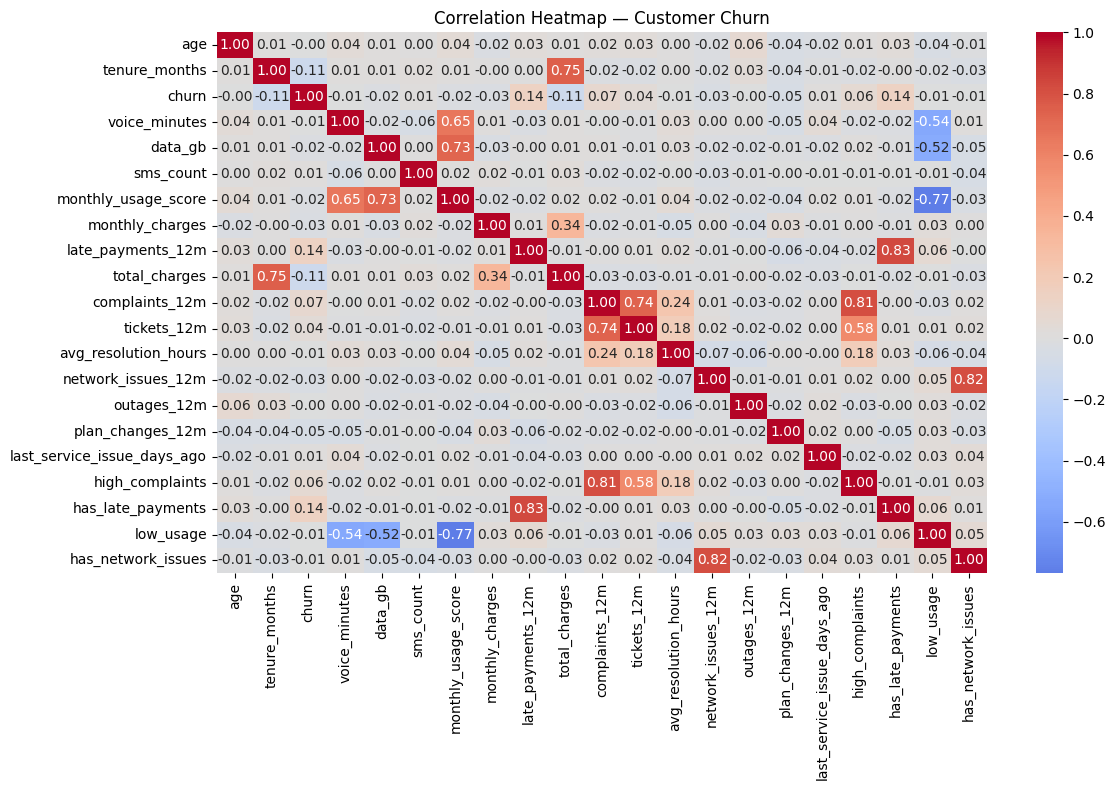

Features correlated with churn:


,Correlation with churn
late_payments_12m,0.141297
has_late_payments,0.136894
tenure_months,-0.113202
total_charges,-0.108667
complaints_12m,0.069543
high_complaints,0.056550
plan_changes_12m,-0.053248
tickets_12m,0.039062
network_issues_12m,-0.034401
monthly_charges,-0.027588


In [19]:

numeric_data = churn_data.select_dtypes(include="number")
correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap — Customer Churn")
plt.tight_layout()
plt.show()

# Show numeric features most correlated with churn
print("Features correlated with churn:")
display(
    correlation["churn"]
    .drop("churn")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation with churn")
)


In [20]:

from google.colab import files

churn_data.to_csv(
    "/content/final_churn_analysis_dataset.csv",
    index=False
)

files.download("/content/final_churn_analysis_dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

!pip -q install openpyxl xlsxwriter


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.6 MB/s eta 0:00:00


In [22]:

import pandas as pd
import numpy as np

from google.colab import files

# Use the analyzed dataset from the previous steps
df = churn_data.copy()

# Create churn labels
df["churn_label"] = df["churn"].map({
    0: "Retained",
    1: "Churned"
})

# Helper function for grouped churn analysis
def churn_summary(column):
    result = df.groupby(column, dropna=False).agg(
        customers=("customer_id", "nunique"),
        churned=("churn", "sum"),
        churn_rate=("churn", "mean")
    ).reset_index()

    result["churn_rate"] = result["churn_rate"] * 100
    return result

# Build summaries using available columns
summaries = {
    "Overall Summary": pd.DataFrame({
        "Metric": [
            "Total Customers",
            "Churned Customers",
            "Retained Customers",
            "Overall Churn Rate (%)"
        ],
        "Value": [
            df["customer_id"].nunique(),
            int(df["churn"].sum()),
            int((df["churn"] == 0).sum()),
            round(df["churn"].mean() * 100, 2)
        ]
    })
}

# Add analysis sheets where the relevant columns exist
for col, sheet in [
    ("plan", "Churn by Plan"),
    ("tenure_group", "Churn by Tenure"),
    ("region", "Churn by Region"),
    ("payment_status", "Churn by Payment")
]:
    if col in df.columns:
        summaries[sheet] = churn_summary(col)

# Complaint analysis
if "complaints_12m" in df.columns:
    summaries["Complaint Analysis"] = df.groupby(
        "churn_label", dropna=False
    ).agg(
        customers=("customer_id", "nunique"),
        avg_complaints=("complaints_12m", "mean"),
        avg_tickets=("tickets_12m", "mean")
    ).reset_index()

# Payment behavior analysis
if "late_payments_12m" in df.columns:
    summaries["Late Payments"] = df.groupby(
        "churn_label", dropna=False
    ).agg(
        customers=("customer_id", "nunique"),
        avg_late_payments=("late_payments_12m", "mean")
    ).reset_index()

# Create workbook
output_file = "/content/Customer_Churn_Insight.xlsx"

with pd.ExcelWriter(
    output_file, engine="xlsxwriter"
) as writer:
    df.to_excel(
        writer, sheet_name="Cleaned Data", index=False
    )

    for sheet, table in summaries.items():
        table.to_excel(
            writer, sheet_name=sheet[:31], index=False
        )

    workbook = writer.book
    header_format = workbook.add_format({
        "bold": True,
        "text_wrap": True,
        "valign": "vcenter",
        "border": 1,
        "bg_color": "#D9EAD3"
    })

    for worksheet in writer.sheets.values():
        worksheet.freeze_panes(1, 0)
        worksheet.autofilter(
            0, 0,
            max(worksheet.dim_rowmax, 0),
            max(worksheet.dim_colmax, 0)
        )
        worksheet.set_column("A:Z", 18)
        worksheet.set_row(0, 30, header_format)

print("Excel workbook created:", output_file)
files.download(output_file)


/tmp/ipykernel_1439/143540287.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df.groupby(column, dropna=False).agg(


Excel workbook created: /content/Customer_Churn_Insight.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

from google.colab import files

files.download("/content/Customer_Churn_Insight.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>